# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 4a: Baseline - Skema 1 "Embeddings"
Word2Vec level kata (dilatih dari data train) + rata-rata vektor kata + Logistic Regression

Vocabulary & Word2Vec dibangun dari train saja.

Aturan: satu run, tanpa grid search; evaluasi hanya di validation; test set tidak disentuh.

- Input : `data/train.csv`, `data/val.csv`, `data/label_map.json`
- Output: `outputs/baseline_embeddings_val_results.json`, `outputs/models/word2vec_128.model`, grafik di `outputs/figures/`

### Step 1 - Konfigurasi, seed, dan load data

In [1]:
import os, json, re, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                            classification_report, confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = "data"
FIG_DIR = "outputs/figures"
MODEL_DIR = "outputs/models"
RESULT_PATH = "outputs/baseline_embeddings_val_results.json"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42

# Tokenisasi & vocabulary: sama dengan yang dipakai TextCNN/BiLSTM (kata + tanda baca/emotikon jadi token sendiri)
TOKEN_PATTERN = r"\w+|[^\w\s]"
MIN_COUNT = 2 # token muncul < 2x di train diabaikan (sama dengan MIN_FREQ di TextCNN/BiLSTM)

# Hyperparameter Word2Vec: nilai wajar yang tetap, tanpa tuning
VECTOR_SIZE = 128 # dimensi embedding (sama dengan nn.Embedding di TextCNN/BiLSTM Skema 1)
WINDOW = 5 # jendela konteks
SG = 1 # 1 = skip-gram (lebih baik untuk korpus kecil), 0 = CBOW
W2V_EPOCHS = 30 # korpus kecil -> butuh lebih banyak epoch daripada default (5)

for d in (FIG_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")

with open(f"{DATA_DIR}/label_map.json") as f:
    label_map = json.load(f)
labels = list(label_map.keys()) # urutan: anger, fear, joy, love, neutral, sad
y_train, y_val = train_df[LABEL_COL], val_df[LABEL_COL]
print("Train:", train_df.shape, "| Val:", val_df.shape, "| Kelas:", labels)

Train: (4921, 2) | Val: (1055, 2) | Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 2 - Tokenisasi

In [2]:
TOKEN_RE = re.compile(TOKEN_PATTERN)
def tokenize(text):
    return TOKEN_RE.findall(text)

train_tokens = [tokenize(t) for t in train_df[TEXT_COL]]
val_tokens = [tokenize(t) for t in val_df[TEXT_COL]]

n_tok_train = sum(len(t) for t in train_tokens)
print("Contoh teks:", train_df[TEXT_COL][0][:80])
print("Token:", train_tokens[0][:12])
print(f"Total token train: {n_tok_train:,} | rata-rata {n_tok_train/len(train_tokens):.1f} token/teks")

Contoh teks: 365. kalau mau gestun limit kamu di spaylater, gopay coin, gopaylater, akulaku, 
Token: ['365', '.', 'kalau', 'mau', 'gestun', 'limit', 'kamu', 'di', 'spaylater', ',', 'gopay', 'coin']
Total token train: 95,854 | rata-rata 19.5 token/teks


### Step 3 - Latih Word2Vec (HANYA dari corpus train)
Word2Vec dipilih dan bukan FastText supaya setara dengan `nn.Embedding` -> keduanya hanya mengenal kata yang ada di vocabulary train, dan kata baru di validation dianggap tidak dikenal. FastText bisa membangun vektor kata baru dari potongan huruf, dan itu akan memberi baseline keunggulan yang tidak dimiliki TextCNN/BiLSTM.

In [3]:
# workers=1 + seed agar hasil bisa direproduksi (multithread di gensim membuat hasil sedikit berubah tiap run)
w2v = Word2Vec(sentences=train_tokens, vector_size=VECTOR_SIZE, window=WINDOW, min_count=MIN_COUNT,
                sg=SG, epochs=W2V_EPOCHS, workers=1, seed=SEED)
wv = w2v.wv
print("Ukuran vocabulary Word2Vec:", len(wv), "| dimensi:", wv.vector_size)

# Bukti: vocabulary = token train dengan frekuensi >= MIN_COUNT (tidak ada token dari validation)
counter = Counter(tok for t in train_tokens for tok in t)
vocab_train = {w for w, c in counter.items() if c >= MIN_COUNT}
assert set(wv.key_to_index) == vocab_train, "Vocabulary Word2Vec tidak sama dengan vocabulary train"
print("Vocabulary Word2Vec identik dengan vocabulary train (min_count =", MIN_COUNT, ").")

# Bukti tambahan: skema vocabulary sama dengan TextCNN/BiLSTM (kalau vocab_nn.json hasil dari notebook 05a atau 06a tersedia)
p = f"{DATA_DIR}/vocab_nn.json"
if os.path.exists(p):
    with open(p, encoding="utf-8") as f: itos = json.load(f)["itos"]
    print("Sama dengan vocab_nn.json (tanpa <pad>/<unk>):", set(itos[2:]) == set(wv.key_to_index))

Ukuran vocabulary Word2Vec: 5714 | dimensi: 128
Vocabulary Word2Vec identik dengan vocabulary train (min_count = 2 ).
Sama dengan vocab_nn.json (tanpa <pad>/<unk>): True


In [4]:
# Sanity check: apakah embedding yang dilatih masuk akal? (tetangga terdekat beberapa kata emosi)
for kata in ["sedih", "marah", "senang", "takut", "cinta"]:
    if kata in wv:
        print(f"{kata:8s} ->", [w for w, _ in wv.most_similar(kata, topn=5)])

sedih    -> ['fak', 'yahh', 'aduk', 'nikmat', 'berita']
marah    -> ['kasar', 'ngambek', 'songong', 'makk', 'ngemis']
senang   -> ['wc', 'jim', 'berita', 'kenyang', 'bercampur']
takut    -> ['meluk', 'mukanya', 'guanya', 'kambuh', 'kelupaan']
cinta    -> ['jatuh', 'cintaan', 'ggvk', 'benih', 'padaku']


### Step 4 - Representasi dokumen = rata-rata vektor kata

In [ ]:
def doc_vector(tokens):
    """Rata-rata vektor kata penyusun teks. Token yang tidak ada di vocabulary (OOV) dilewati.
    Jika semua token OOV -> vektor nol."""
    vecs = [wv[t] for t in tokens if t in wv]
    if not vecs:
        return np.zeros(VECTOR_SIZE, dtype=np.float32)
    return np.mean(vecs, axis=0)

def featurize(token_lists):
    return np.vstack([doc_vector(t) for t in token_lists])

X_train = featurize(train_tokens)
X_val = featurize(val_tokens) # validation hanya memakai Word2Vec dari train (tanpa melatih ulang)

nol_train = int((np.abs(X_train).sum(axis=1) == 0).sum())
nol_val = int((np.abs(X_val).sum(axis=1) == 0).sum())
tok_val_flat = [t for ts in val_tokens for t in ts]
cakupan_val = np.mean([t in wv for t in tok_val_flat])

print("Matriks fitur train:", X_train.shape, "| val:", X_val.shape)
pd.DataFrame({
    "pemeriksaan": ["Cakupan token validation oleh vocabulary", "Teks train dengan vektor nol", "Teks validation dengan vektor nol"],
    "nilai": [f"{cakupan_val*100:.2f}%", nol_train, nol_val],
})

Matriks fitur train: (4921, 128) | val: (1055, 128)


,pemeriksaan,nilai
0,Cakupan token validation oleh vocabulary,85.55%
1,Teks train dengan vektor nol,1
2,Teks validation dengan vektor nol,1


### Step 5 - Logistic Regression (multiclass)

In [6]:
# Standarisasi fitur (fit hanya pada train): rata-rata vektor kata berskala kecil, standarisasi membantu
# Logistic Regression konvergen. Bukan tuning; kedua skema baseline (04b dan 04c) memakai langkah yang sama.
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

# Logistic Regression default sklearn, tanpa tuning (setelan sama dengan baseline Skema 2 di 04c)
clf = LogisticRegression(max_iter=1000, random_state=SEED)
clf.fit(X_train_s, y_train)
print("Model terlatih. Kelas:", list(clf.classes_))

Model terlatih. Kelas: ['anger', 'fear', 'joy', 'love', 'neutral', 'sad']


### Step 6 - Evaluasi di validation set

In [7]:
y_pred = clf.predict(X_val_s)

acc = accuracy_score(y_val, y_pred)
macro_p = precision_score(y_val, y_pred, average="macro", zero_division=0)
macro_r = recall_score(y_val, y_pred, average="macro", zero_division=0)
macro_f1 = f1_score(y_val, y_pred, average="macro")

kelas_terbanyak = y_train.value_counts().idxmax()
print(f"Acuan 'tebak selalu {kelas_terbanyak}': accuracy = {(y_val == kelas_terbanyak).mean():.4f}")
print(f"Baseline Skema 1 (val): accuracy = {acc:.4f} | macro-F1 = {macro_f1:.4f}")

# Satu tabel: per kelas + accuracy + macro avg + weighted avg
rapor = classification_report(y_val, y_pred, labels=labels, output_dict=True, zero_division=0)
rapor_df = pd.DataFrame(rapor).T.drop(index="accuracy")
rapor_df.loc["accuracy"] = [np.nan, np.nan, acc, len(y_val)] # accuracy ditulis di kolom f1-score (konvensi sklearn)
rapor_df = rapor_df.loc[labels + ["accuracy", "macro avg", "weighted avg"]]
rapor_df["support"] = rapor_df["support"].astype(int)
rapor_df.round(4).fillna("")

Acuan 'tebak selalu neutral': accuracy = 0.2825
Baseline Skema 1 (val): accuracy = 0.6512 | macro-F1 = 0.6588


,precision,recall,f1-score,support
anger,0.6327,0.5536,0.5905,168
fear,0.7636,0.6176,0.6829,136
joy,0.7569,0.5767,0.6547,189
love,0.6357,0.7876,0.7036,113
neutral,0.5767,0.6812,0.6246,298
sad,0.6728,0.7219,0.6965,151
accuracy,,,0.6512,1055
macro avg,0.6731,0.6564,0.6588,1055
weighted avg,0.6621,0.6512,0.6508,1055


### Step 7 - Confusion matrix (validation)

,pred_anger,pred_fear,pred_joy,pred_love,pred_neutral,pred_sad
asli_anger,93,6,5,11,47,6
asli_fear,10,84,4,7,27,4
asli_joy,5,9,109,13,40,13
asli_love,5,0,5,89,12,2
asli_neutral,26,10,16,15,203,28
asli_sad,8,1,5,5,23,109


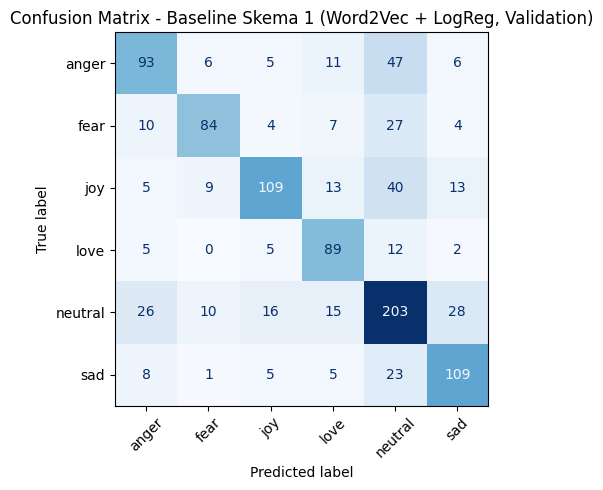

In [8]:
cm = confusion_matrix(y_val, y_pred, labels=labels)
display(pd.DataFrame(cm, index=[f"asli_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Baseline Skema 1 (Word2Vec + LogReg, Validation)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04a_confusion_matrix_baseline_embeddings_val.png", dpi=150)
plt.show()

### Step 8 - Simpan hasil

In [9]:
# Format JSON seragam untuk 6 kombinasi (kunci inti sama: model, feature_extraction, split, accuracy, macro_*)
with open(RESULT_PATH, "w") as f:
    json.dump({"model": "Baseline (LogReg)", "feature_extraction": "embeddings", "split": "validation",
                "accuracy": round(float(acc), 4), "macro_precision": round(float(macro_p), 4),
                "macro_recall": round(float(macro_r), 4), "macro_f1": round(float(macro_f1), 4),
                "extractor": "Word2Vec skip-gram (gensim, dari train) + mean pooling",
                "n_features": int(VECTOR_SIZE), "vocab_size": int(len(wv))}, f, indent=2)
print("Tersimpan:", RESULT_PATH)

w2v.save(f"{MODEL_DIR}/word2vec_{VECTOR_SIZE}.model")
print("Tersimpan:", f"{MODEL_DIR}/word2vec_{VECTOR_SIZE}.model")

Tersimpan: outputs/baseline_embeddings_val_results.json
Tersimpan: outputs/models/word2vec_128.model


### Notes Part 4a:
- Vocabulary Word2Vec (train) | dimensi: 5714 | 128
- Cakupan token validation oleh vocabulary: 85.55%
- Accuracy | Macro-F1 (validation): 0.6512 | 0.6588
- Macro-Precision | Macro-Recall: 0.6731 | 0.6564
- F1 tertinggi | terendah per kelas: love (0.7036) | anger (0.5905)
- Pasangan kelas yang paling sering tertukar: anger dan neutral (73 kesalahan di dua arah)
- Test set belum disentuh